 # The central limit theorem and Monte Carlo Error

 This notebook explores one of the modt important theorems in statistics **Central Limit Theorem (CLT)** and its crucial role in understanding **Monte Carlo simulation error**.

# Setup: Import libraries

In [2]:
pip install seaborn

   ---------------------------------------- 0.0/9.8 MB ? eta -:--:--
   --------- ------------------------------ 2.4/9.8 MB 11.8 MB/s eta 0:00:01
   ------------------- -------------------- 4.7/9.8 MB 11.8 MB/s eta 0:00:01
   ----------------------------- ---------- 7.3/9.8 MB 11.6 MB/s eta 0:00:01
   ---------------------------------------  9.7/9.8 MB 11.7 MB/s eta 0:00:01
   ---------------------------------------- 9.8/9.8 MB 10.8 MB/s  0:00:00

   ---------------------------------------- 0/3 [tzdata]
   ---------------------------------------- 0/3 [tzdata]
   ---------------------------------------- 0/3 [tzdata]
   ---------------------------------------- 0/3 [tzdata]
   ---------------------------------------- 0/3 [tzdata]
   ------------- -------------------------- 1/3 [pandas]
   ------------- -------------------------- 1/3 [pandas]
   ------------- -------------------------- 1/3 [pandas]
   ------------- -------------------------- 1/3 [pandas]
   ------------- ------------------

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import norm
import warnings
warnings.filterwarnings("ignore")

# set style for beautiful plots
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
np.random.seed(42)

# configure plot aesthetics
plt.rcParams['figure.figsize'] = [12, 6]
plt.rcParams['font.size'] = 11
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['axes.titlesize'] = 12

print("All libraries imported and configurations set successfully.")
print("Ready to perform statistical analysis and visualization.")

All libraries imported and configurations set successfully.
Ready to perform statistical analysis and visualization.


<a id="1. Introduction></a>
## 1. Introduction to the central limit theorem

### The theorem Statement
 > **Central Limit Theorem**: Let $X_1, X_2, \ldots, X_n$ be independent and identically distributed (i.i.d) random variables with mean $\mu$ and finite variance $\sigma^2$.
 Then, as $n \to \infty$:
 >
 > $$\frac{\bar{X}_n - \mu}{\sigma /\sqrt{n}} \xrightarrow{d} \mathcal{N}(0,1)$$
 >
 > Or equivalently : $\bar{X}_n \xrightarrow{d} \mathcal{N}\left(\mu, \frac{\sigma^2}{n}\right)$

 ### Intuitive Understanding

The CLT tells us something remarkable:

**No matter what distribution your data comes from**, if you:
1. Take many random samples of size $n$
2. Calculate the mean of each sample
3. Look at the distribution of those sample means

**The distribution of sample means will be approximately Normal!**

### Key Properties:
- The mean of sample means equal to the population mean: $E[\bar{X}] = \mu$
- The standard deviation of sample means (standard error): $SE = \frac{\sigma}{\sqrt{n}}$
- Larger samples -> narrower ditribution of sample means
- Works for ant distribution with finite variance

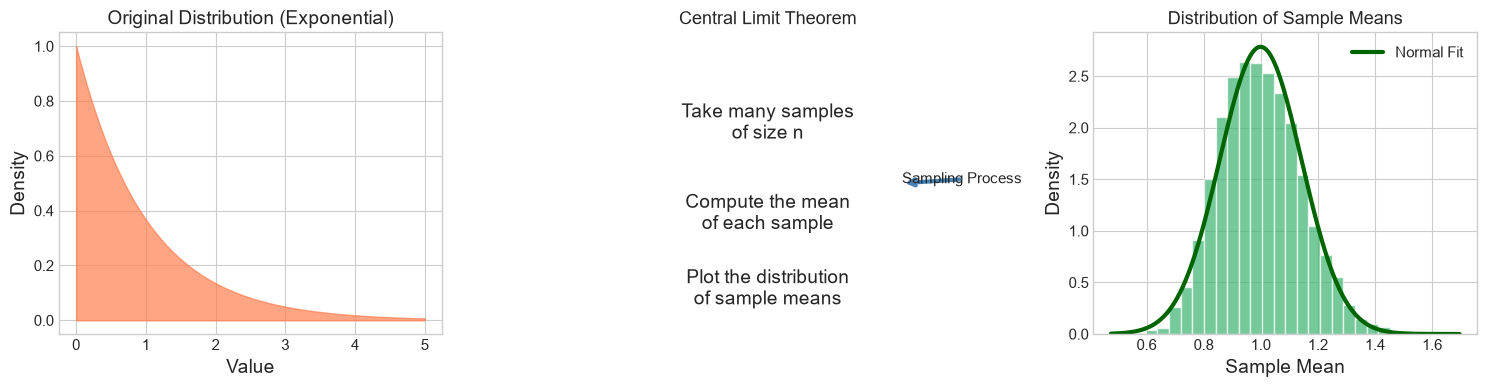

Central Limit Theorem visualization created and saved successfully!


In [5]:
# Visual: The CLT in one picture
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Original distribution (very non-normal)
x = np.linspace(0,5,1000)
original = stats.expon.pdf(x, scale=1)
axes[0].fill_between(x, original, color='coral', alpha=0.7)
axes[0].set_title('Original Distribution (Exponential)', fontsize=14)
axes[0].set_xlabel('Value')
axes[0].set_ylabel('Density')

# Sampling process
axes[1].annotate('Sampling Process', xy=(0.85, 0.5),arrowprops=dict(arrowstyle='->', lw=3, color='steelblue'), xycoords='axes fraction')
axes[1].text(0.5, 0.7, 'Take many samples\nof size n',fontsize=14, ha='center', va='center', transform=axes[1].transAxes)
axes[1].text(0.5, 0.4, 'Compute the mean\nof each sample',fontsize=14, ha='center', va='center', transform=axes[1].transAxes)
axes[1].text(0.5, 0.15, 'Plot the distribution\nof sample means',fontsize=14, ha='center', va='center', transform=axes[1].transAxes)
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1)
axes[1].axis('off')
axes[1].set_title('Central Limit Theorem', fontsize=13)

# Distribution of sample means
sample_means = [np.mean(np.random.exponential(scale=1, size=50)) for _ in range(5000)]
axes[2].hist(sample_means, bins=30, density=True, alpha=0.7, color='mediumseagreen', edgecolor='white')
x_norm = np.linspace(min(sample_means), max(sample_means), 1000)
y_norm = stats.norm.pdf(x_norm, loc=np.mean(sample_means), scale=np.std(sample_means))
axes[2].plot(x_norm, y_norm, color='darkgreen', linewidth=3, label='Normal Fit')
axes[2].set_title('Distribution of Sample Means', fontsize=13)
axes[2].set_xlabel('Sample Mean')
axes[2].set_ylabel('Density')
axes[2].legend()

plt.tight_layout()
plt.savefig('reports/clt_visualization.png', dpi=300)
plt.show()
print("Central Limit Theorem visualization created and saved successfully!")

<a id ="2-Monte-Carlo-Error"></a>
## 2. CLT and Monte Carlo Error

#### What is Monte Carlo simulation?
Monte Carlo methods estimate unknown quantities using **random sampling**. For example, to estimate $E(f(X))$:

$$\hat{\mu}_n = \frac{1}{n} \sum_{i=1}^{n} f(X_i)$$

### The $1/\sqrt{n}$ Convergence rate

The CLT directly explains **why Monte Carlo error decreases at rate $1/\sqrt{n}$**:

From the CLT, we know:
$$\text{Standard Error} = \frac{\sigma}{\sqrt{n}} $$

This has profound implication:
| Samples (n) | Relative Error | Improvement |
|-------------|----------------|-------------|
| 100 | $\sigma/10$ | baseline
| 10,000 | $\sigma/100$ | 10x better |
| 1,000,000 | $\sigma/1000$ | 100x better |

### The Bad News: Diminishing Returns

To reduce error by a factor of 10, you need **100x more samples**!

$$\text{Error reduction factor} = \sqrt{\frac{n_{\text{new}}}{n_{\text{old}}}} $$

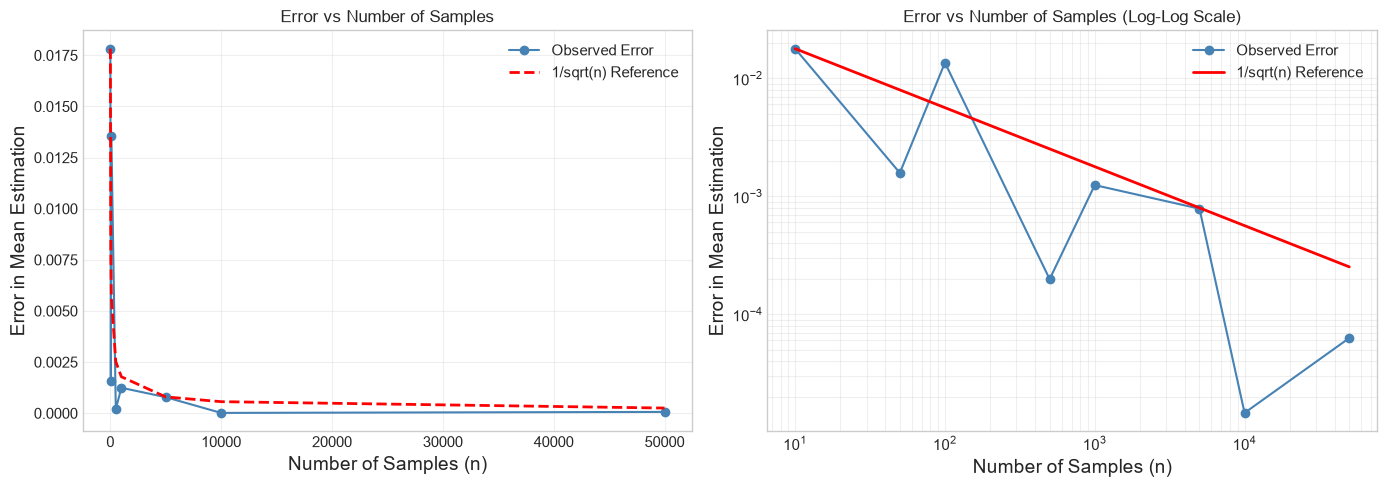

In [8]:
# Demonstrate the 1/sqrt(n) convergence rate
n_values= np.array([10, 50, 100, 500, 1000, 5000, 10000, 50000])
n_simulations = 500

# estimate mean of exponential distribution
true_mean = 1.0
errors = []

for n in n_values:
    sample_means = [np.mean(np.random.exponential(scale=1, size=n)) for _ in range(n_simulations)]
    error = np.abs(np.mean(sample_means) - true_mean)
    errors.append(error)

errors = np.array(errors)
# plot error vs n with 1/sqrt(n) reference
fig, ax = plt.subplots(1, 2,figsize=(14, 5))

ax[0].plot(n_values, errors, marker='o', linestyle='-', color='steelblue', label='Observed Error')
theoretical_errors = errors[0]*np.sqrt(n_values[0]) /np.sqrt(n_values)
ax[0].plot(n_values, theoretical_errors,  'r--', linewidth=2, label='1/sqrt(n) Reference')
ax[0].set_xlabel('Number of Samples (n)')
ax[0].set_ylabel('Error in Mean Estimation')
ax[0].set_title('Error vs Number of Samples')
ax[0].legend()
ax[0].grid(True, alpha=0.3)

ax[1].loglog(n_values, errors, marker='o', linestyle='-', color='steelblue', label='Observed Error')
ax[1].loglog(n_values, theoretical_errors, 'r-', linewidth=2, label='1/sqrt(n) Reference')
ax[1].set_xlabel('Number of Samples (n)')   
ax[1].set_ylabel('Error in Mean Estimation')
ax[1].set_title('Error vs Number of Samples (Log-Log Scale)')
ax[1].legend()
ax[1].grid(True, alpha=0.3, which='both')

# Add slope annotation
ax[1].annotate('Slope = -0.5', xy=(1000, 0.03), fontsize=12, color='red')

plt.tight_layout()
plt.savefig('reports/error_convergence.png', dpi=150, bbox_inches='tight')
plt.show()


<a id="3- estimate-pi"></a>
## 3. Monte Carlo Estimation of $\pi$

A classic Monte Carlo example: **estimating $\pi$ using random sampling!**

### The Method
1. Generate random points $(x,y)$ uniformly in a square $[0,1] \times [0,1]$
2. Count how many fall inside the quarter circle: $x^2 + y^2 \leq 1$
3. The ratio of points inside ~ area of quarter circle / area of square =$\pi/4$

$$\hat{\pi} = 4 \times \frac{\text{points inside the circle}}{\text{total points}}$$

### Applying CLT

Each point is a Bernoulli trial with $p = \pi/4$. By the CLT:
- Standard error of $\hat{p} = \sqrt{\frac{p(1-p)}{n}}$
- Standard error of $\hat{\pi} = 4 \times \sqrt{\frac{p(1-p)}{n}} $

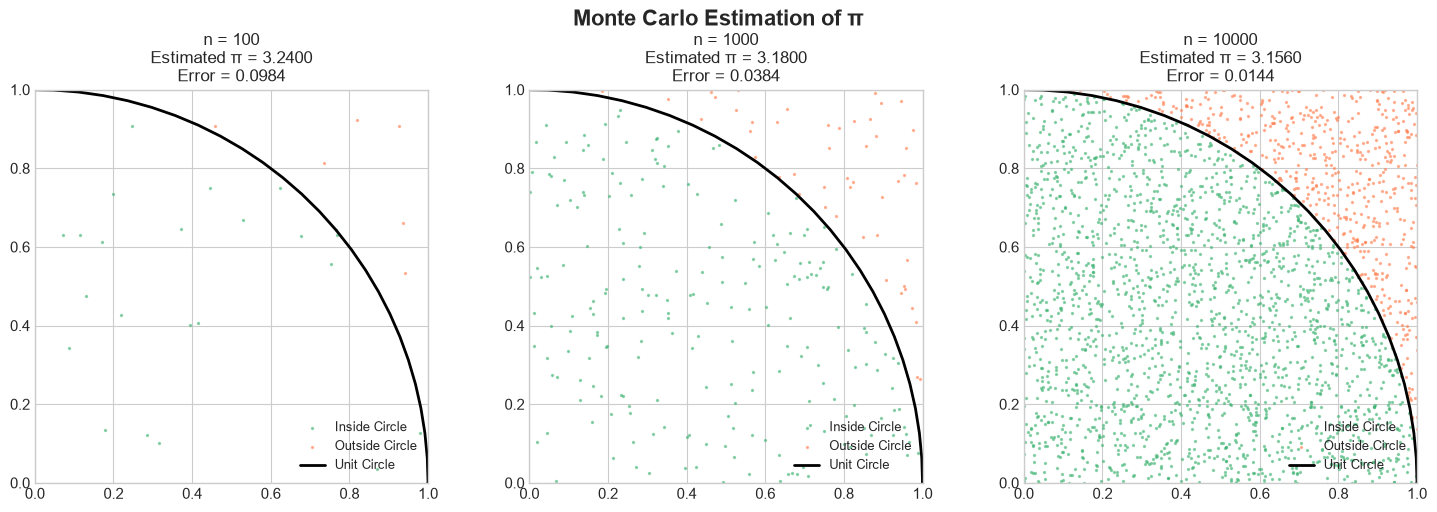

In [9]:
def estimate_pi(n_points):
    # estimate pi using Monte Carlo method
    x = np.random.uniform(-1, 1, n_points)
    y = np.random.uniform(-1, 1, n_points)
    inside_circle = (x**2 + y**2) <= 1
    pi_estimate = 4 * np.sum(inside_circle) / n_points
    return pi_estimate, x, y, inside_circle

# visualize the Monte Carlo estimation of pi
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, n_points in enumerate([100, 1000, 10000]):
    pi_estimate, x, y, inside_circle = estimate_pi(n_points)
    plot_n =min(n_points, 10000)  # limit the number of points plotted for clarity
    axes[i].scatter(x[:plot_n][inside_circle[:plot_n]], y[:plot_n][inside_circle[:plot_n]], color='mediumseagreen', s=2, alpha= 0.5, label='Inside Circle')
    axes[i].scatter(x[:plot_n][~inside_circle[:plot_n]], y[:plot_n][~inside_circle[:plot_n]], color='coral', s=2, alpha= 0.5, label='Outside Circle')
    theta = np.linspace(0, 2 * np.pi, 100)
    axes[i].plot(np.cos(theta), np.sin(theta), 'k-', linewidth=2, label='Unit Circle')

    error = abs(pi_estimate - np.pi)
    axes[i].set_title(f'n = {n_points}\nEstimated π = {pi_estimate:.4f}\nError = {error:.4f}', fontsize=12)
    axes[i].set_xlim(0, 1)
    axes[i].set_ylim(0, 1)
    axes[i].set_aspect('equal', adjustable='box')
    axes[i].legend(loc='lower right', fontsize=9)

plt.suptitle('Monte Carlo Estimation of π', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('reports/monte_carlo_pi_estimation.png', dpi=150, bbox_inches='tight')
plt.show()

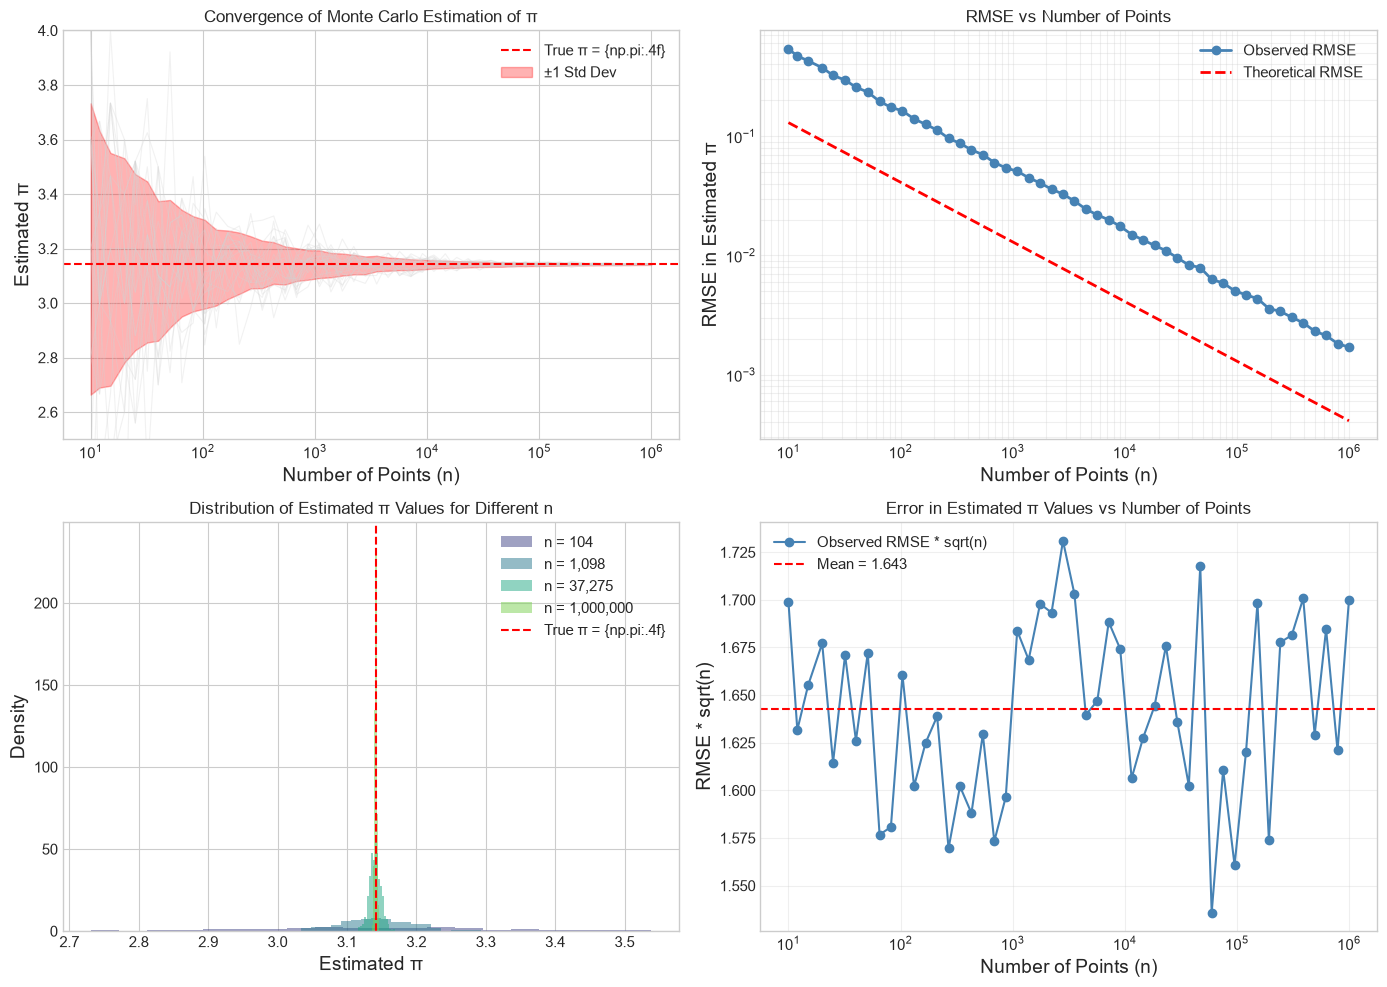

In [11]:
# track convergence and error
n_values = np.logspace(1, 6, 50).astype(int)
n_simulations = 500

estimated_pis = np.zeros((len(n_values), n_simulations))
for i, n in enumerate(n_values):
    for j in range(n_simulations):
        estimated_pis[i, j] = estimate_pi(n)[0]

# calculate mean and standard deviation of estimated pi values
mean_estimated_pis = np.mean(estimated_pis, axis=1)
std_estimated_pis = np.std(estimated_pis, axis=1)
error_estimated_pis = np.abs(mean_estimated_pis - np.pi)
rmse_estimated_pis = np.sqrt(np.mean((estimated_pis - np.pi)**2, axis=1))

# plot convergence and error
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Mean of estimated pi values
ax = axes[0, 0]
for j in range(min(20, n_simulations)):
    ax.semilogx(n_values, estimated_pis[:, j], color='lightgray', alpha=0.3, lw=0.8)
ax.axhline(np.pi, color='red', linestyle='--', label='True π = {np.pi:.4f}')
ax.fill_between(n_values, mean_estimated_pis - std_estimated_pis, mean_estimated_pis + std_estimated_pis, color='red', alpha=0.3, label='±1 Std Dev')
ax.set_xlabel('Number of Points (n)')
ax.set_ylabel('Estimated π')
ax.set_title('Convergence of Monte Carlo Estimation of π')
ax.legend()
ax.set_ylim(2.5, 4.0)

# RMSE in estimated pi values
ax = axes[0, 1]
ax.loglog(n_values, rmse_estimated_pis, marker='o', linestyle='-', color='steelblue', lw=2, label='Observed RMSE')
# theoretical 
p = np.pi/4
theoretical_rmse = np.sqrt(p*(1-p)/n_values)
ax.loglog(n_values, theoretical_rmse, 'r--', linewidth=2, label='Theoretical RMSE')
ax.set_xlabel('Number of Points (n)')
ax.set_ylabel('RMSE in Estimated π')
ax.set_title('RMSE vs Number of Points')
ax.legend()
ax.grid(True, alpha=0.3, which='both')

# Distribution of estimated pi values for n
ax = axes[1, 0]
colors = plt.cm.viridis(np.linspace(0.2, 0.8, 4))
for i, n_idx in enumerate([10, 20, 35, 49]):
    n = n_values[n_idx]
    ax.hist(estimated_pis[n_idx, :], bins=20, density=True, alpha=0.5, color=colors[i], label=f'n = {n:,}')
ax.axvline(np.pi, color='red', linestyle='--', label='True π = {np.pi:.4f}')
ax.set_xlabel('Estimated π')
ax.set_ylabel('Density')
ax.set_title('Distribution of Estimated π Values for Different n')
ax.legend()

# Error in estimated pi values for n
ax = axes[1, 1]
scaled_errors = rmse_estimated_pis * np.sqrt(n_values)
ax.semilogx(n_values, scaled_errors, marker='o', linestyle='-', color='steelblue', lw=1.5, label='Observed RMSE * sqrt(n)')
ax.axhline(np.mean(scaled_errors[10:]), color='red', linestyle='--', label=f'Mean = {np.mean(scaled_errors[10:]):.3f}')
ax.set_xlabel('Number of Points (n)')
ax.set_ylabel('RMSE * sqrt(n)')
ax.set_title('Error in Estimated π Values vs Number of Points')
ax.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('reports/monte_carlo_pi_convergence_analysis.png', dpi=150, bbox_inches='tight')    
plt.show()



<a id = "4- confidence-interval"></a>
## 5. Confidence Intervals: Quantifying Monte Carlo Uncertainty

The CLT allows us to construct **confidence intervals** for Monte Carlo estimates:

### Formula for $(1-\alpha)$ Confidence Interval

$$\bar{X}_n \pm z_{\alpha/2} \cdot \frac{\hat{\sigma}}{\sqrt{n}} $$

Where:
- $\bar{X}_n$ = sample mean (our estimate)
- $z_{\alpha/2}$ = critical value (1.96 for 95% CI)
- $\hat{\sigma}$ = sample standard deviation
- $n$ = number of samples

### Why this works
By the CLT, $\bar{X}_n$ is approximately normal, so:

$$\left(\bar{X}_n - z_{\alpha/2} \cdot \frac{\sigma}{\sqrt{n}} \leq \mu \leq \bar{X}_n + z_{\alpha/2} \cdot \frac{\sigma}{\sqrt{n}} \right) \approx 1- \alpha$$

In [12]:
def monte_carlo_with_ci(estimator, true_value, n_samples, confidence= 0.95):
    """ Run Monte Carlo simulations to estimate a parameter and compute confidence intervals."""
    samples = estimator(n_samples)
    estimate = np.mean(samples)
    std_estimate = np.std(samples, ddof=1)
    se = std_estimate / np.sqrt(n_samples)  # standard error

    # Compute confidence interval
    z_score = norm.ppf(1 - (1 - confidence) / 2)
    ci_lower = estimate - z_score * se
    ci_upper = estimate + z_score * se

    return {
        'estimate_pi': estimate,
        'se': se,
        'ci' : (ci_lower, ci_upper),
        'ci_width': ci_upper - ci_lower,
        'contains_true': ci_lower <= true_value <= ci_upper
    }

# example
estimator = lambda n: np.random.normal(0, 1, n)**2  # standard normal distribution
true_value = 1.0  # variance of standard normal distribution

for n in [100, 500, 1000, 5000, 10000]:
    result = monte_carlo_with_ci(estimator, true_value, n)
    ci_str = f"[{result['ci'][0]:.4f}, {result['ci'][1]:.4f}]"
    contains_true_str = "Yes" if result['contains_true'] else "No"
    print(f"n = {n}: Estimate = {result['estimate_pi']:.4f}, SE = {result['se']:.4f}, CI = {ci_str}, Width = {result['ci_width']:.4f}, Contains True Value: {contains_true_str}")

n = 100: Estimate = 0.8292, SE = 0.1056, CI = [0.6222, 1.0362], Width = 0.4140, Contains True Value: Yes
n = 500: Estimate = 1.0350, SE = 0.0651, CI = [0.9074, 1.1626], Width = 0.2553, Contains True Value: Yes
n = 1000: Estimate = 0.9116, SE = 0.0401, CI = [0.8330, 0.9903], Width = 0.1572, Contains True Value: No
n = 5000: Estimate = 0.9881, SE = 0.0191, CI = [0.9508, 1.0255], Width = 0.0747, Contains True Value: Yes
n = 10000: Estimate = 1.0065, SE = 0.0141, CI = [0.9788, 1.0342], Width = 0.0554, Contains True Value: Yes


Actual coverage over 1000 experiments: 94.30%


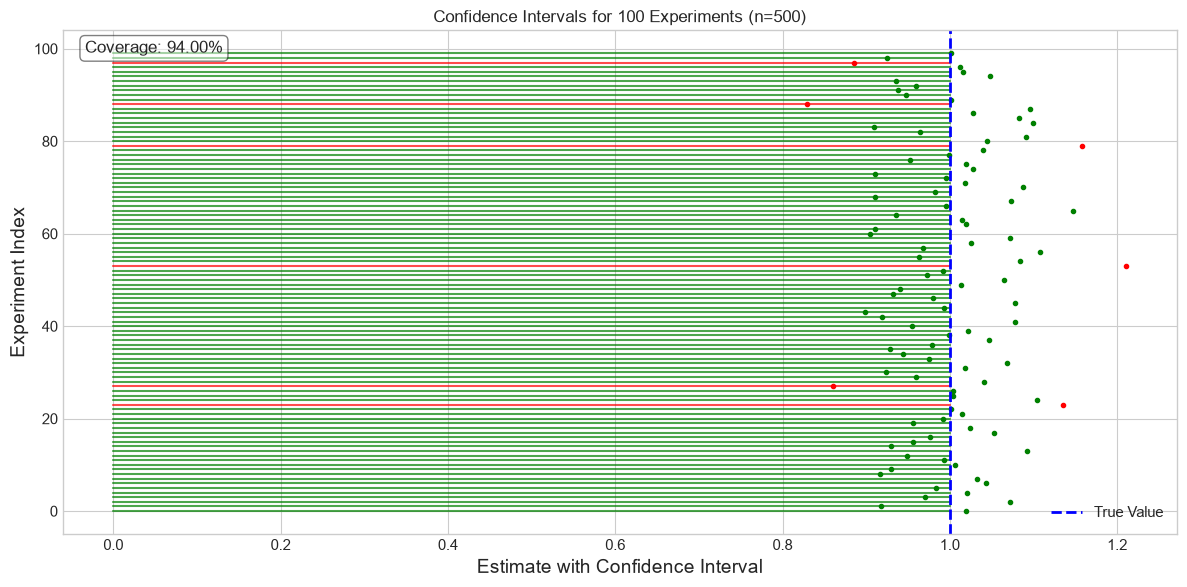

In [14]:
# verify 95% CI coverage
n_experiments = 1000
n_samples = 500
confidence_level = 0.95
coverage_count = []
for _ in range(n_experiments):
    result = monte_carlo_with_ci(estimator, true_value, n_samples, confidence=confidence_level)
    coverage_count.append(result['contains_true'])

actual_coverage = np.mean(coverage_count)
print(f"Actual coverage over {n_experiments} experiments: {actual_coverage:.2%}")

# visualize many CIs
fig, axes = plt.subplots(figsize=(12, 6))
n_show = 100
cis = []
estimates = []
contains_true = []

for i in range(n_show):
    result = monte_carlo_with_ci(estimator, true_value, n_samples, confidence=confidence_level)
    cis.append(result['ci'])
    estimates.append(result['estimate_pi'])
    contains_true.append(result['contains_true'])

#plot CIs
for i in range(n_show):
    color = 'green' if contains_true[i] else 'red'
    axes.plot(cis[i][0], cis[i][1], [i,i], color=color, lw=1.5, alpha=0.7)
    axes.plot(estimates[i], i, 'o', color=color, markersize=3)

axes.axvline(true_value, color='blue', lw=2, linestyle='--', label='True Value')
axes.set_xlabel('Estimate with Confidence Interval')
axes.set_ylabel('Experiment Index')
axes.set_title(f'Confidence Intervals for {n_show} Experiments (n={n_samples})')

coverage = np.mean(contains_true)
axes.text(0.02, 0.98, f'Coverage: {coverage:.2%}', transform=axes.transAxes, fontsize=12, verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.5))
axes.legend(loc='lower right')
plt.tight_layout()
plt.savefig('reports/monte_carlo_ci_visualization.png', dpi=150, bbox_inches='tight')
plt.show()